In [1]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

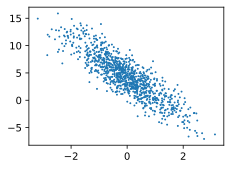

In [2]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = d2l.synthetic_data(true_w, true_b, 1000)

d2l.set_figsize()
d2l.plt.scatter(features[:, 1].detach().numpy(), labels.detach().numpy(), 1);

In [3]:
def load_array(data_arrays, batch_size, is_train=True):  #@save
    """构造一个PyTorch数据迭代器"""
    dataset = data.TensorDataset(*data_arrays)
    return data.DataLoader(dataset, batch_size, shuffle=is_train)

In [4]:
batch_size = 10
data_iter = load_array((features, labels), batch_size)

In [5]:
next(iter(data_iter))

[tensor([[-0.3004,  0.9256],
         [ 0.0839, -0.4079],
         [-0.5973, -0.5129],
         [-0.6389,  1.3774],
         [-0.1404, -0.3205],
         [ 0.2950,  2.5014],
         [-1.3991,  0.7014],
         [-0.2594,  0.1463],
         [ 0.9348,  0.1522],
         [-0.0423, -0.8221]]),
 tensor([[ 0.4631],
         [ 5.7646],
         [ 4.7555],
         [-1.7568],
         [ 5.0072],
         [-3.7108],
         [-0.9780],
         [ 3.1817],
         [ 5.5434],
         [ 6.9124]])]

In [6]:
# 定义模型

from torch import nn

net = nn.Sequential(nn.Linear(2, 1))

# 初始化模型参数

net[0].weight.data.normal_(0, 0.01) # 定义w
net[0].bias.data.fill_(0)  # 定义b

tensor([0.])

In [7]:
# 定义损失函数

loss = nn.MSELoss()

In [8]:
# 优化算法
trainer = torch.optim.SGD(net.parameters(), lr=0.03)

In [9]:
num_epochs = 3
for epoch in range(num_epochs):
    for x,y in data_iter:
        l = loss(net(x), y)
        trainer.zero_grad()
        l.backward()
        trainer.step()
    l = loss(net(features), labels)
    print(f'epoch {epoch + 1}, loss {l:f}')

epoch 1, loss 0.000169
epoch 2, loss 0.000094
epoch 3, loss 0.000095


In [10]:
w = net[0].weight.data
print('w的估计误差：', true_w - w.reshape(true_w.shape))
b = net[0].bias.data
print('b的估计误差：', true_b - b)

w的估计误差： tensor([ 0.0008, -0.0012])
b的估计误差： tensor([0.0007])


In [11]:
w,b

(tensor([[ 1.9992, -3.3988]]), tensor([4.1993]))